# Cap table, rondas y dilución: de los SAFE a la cascada de salida

**Perfil:** Estrategia, innovación y venture capital  
**Datos:** sintéticos con semilla fija; se conoce el proceso generador, así que se puede comprobar si el método recupera la verdad.

## Pregunta que guía el notebook

Los fundadores negocian valoraciones, pero lo que reciben depende de tres mecanismos menos visibles: la **conversión de los SAFE**, el **pool de opciones creado antes de la ronda** y las **preferencias de liquidación** en la salida. ¿Cuánto cuesta cada uno? ¿Cuándo una cláusula "participante" cambia el reparto? ¿Qué valoración *efectiva* se negocia realmente?

## Recorrido

1. Un motor de *cap table* con SAFE post-money (con *cap* y con descuento), *option pool shuffle* y rondas con precio.
2. **Invariantes** verificables: la suma de propiedad es 100 %, el post-money implícito coincide con el pactado, el pool queda en su objetivo.
3. **Valoración efectiva** del pre-money cuando el pool sale del lado de los fundadores.
4. **Trayectoria de dilución** SAFE → Serie A → Serie B.
5. **Cascada de liquidación** con preferencias 1× no participantes, participantes y 2×: puntos de conversión verificados analíticamente.
6. **Monte Carlo de la salida:** pago esperado de los fundadores según los términos de la Serie B.
7. Pruebas y límites.

Las conclusiones numéricas se **calculan y se imprimen desde los datos** (celdas «Lectura»), y las pruebas de la sección final hacen fallar el notebook si un hallazgo deja de cumplirse.

## 1. Configuración

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 2026
plt.rcParams.update({"figure.figsize": (7.5, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format

## 2. El motor de rondas

**SAFE post-money con *cap* $C$**: convierte en una participación $I/C$ de la capitalización de la empresa *incluidos todos los SAFE convertidos* pero **sin** el aumento del pool de la ronda. Con varios SAFE, si $q=\sum I_i/C_i$ y $S_0$ son las acciones previas (incluido el pool existente), la capitalización es $S_0/(1-q)$ y cada SAFE recibe $(I_i/C_i)\cdot S_0/(1-q)$ acciones. Si el SAFE tiene **descuento** $d$, convierte al mejor entre su precio por *cap* y $(1-d)\cdot p$, con $p$ el precio de la ronda.

**Ronda con precio**: pre-money $V_{pre}$, inversión $I$, post-money $V=V_{pre}+I$. El precio es $p=V_{pre}/(\text{acciones previas totalmente diluidas, incluidos los SAFE y el pool nuevo})$ y el **pool** se amplía hasta un objetivo $\pi$ del post-money, *dentro del pre-money* (el *option pool shuffle*). Despejando:
$$p=\frac{V_{pre}-\pi V}{S_0+\text{acciones de SAFE}-\text{pool}_0}.$$
Como el descuento hace depender los SAFE de $p$, se resuelve por iteración de punto fijo.

In [2]:
def convertir_safes(S0, safes, p):
    # acciones por SAFE (post-money con cap y/o descuento). safes: dicts con nombre, inv, cap, desc
    if not safes: return np.array([])
    q = sum(s["inv"] / s["cap"] for s in safes)
    cap_total = S0 / (1 - q)
    return np.array([max(s["inv"] / s["cap"] * cap_total, s["inv"] / ((1 - s["desc"]) * p) if s["desc"] else 0.0) for s in safes])

def ronda_con_precio(tabla, safes, inv, pre, pool_obj, inversor):
    S0 = sum(tabla.values()); pool0 = tabla.get("pool", 0.0); post = pre + inv
    p = pre / S0
    for _ in range(500):
        sh = convertir_safes(S0, safes, p)
        p_nuevo = (pre - pool_obj * post) / (S0 + sh.sum() - pool0)
        if abs(p_nuevo - p) < 1e-13 * p: p = p_nuevo; break
        p = p_nuevo
    sh = convertir_safes(S0, safes, p)
    nueva = dict(tabla)
    for s, x in zip(safes, sh): nueva[s["nombre"]] = x
    pool_nuevo = max(pool_obj * post / p - pool0, 0.0)
    nueva["pool"] = pool0 + pool_nuevo
    nueva[inversor] = inv / p
    return nueva, p, {"pool_nuevo": pool_nuevo, "sh_safe": sh}

def propiedad(tabla):
    tot = sum(tabla.values()); return pd.Series({k: v / tot for k, v in tabla.items()})

FUND = {"fund_A": 6_000_000.0, "fund_B": 4_000_000.0}
SAFES = [{"nombre": "SAFE_1", "inv": 500_000.0, "cap": 5_000_000.0, "desc": 0.0}, {"nombre": "SAFE_2", "inv": 250_000.0, "cap": 8_000_000.0, "desc": 0.20}]
tA, pA, iA = ronda_con_precio(FUND, SAFES, 3_000_000.0, 12_000_000.0, 0.10, "SerieA")
ownA = propiedad(tA)
print(f"Precio de la Serie A: {pA:.4f} USD/accion. Post-money implicito: {sum(tA.values()) * pA:,.0f} (pactado 15,000,000)")
pd.DataFrame({"acciones": pd.Series(tA), "propiedad": ownA, "valor_a_precio_ronda": pd.Series(tA) * pA}).round(4)

Precio de la Serie A: 0.9122 USD/accion. Post-money implicito: 15,000,000 (pactado 15,000,000)


,acciones,propiedad,valor_a_precio_ronda
fund_A,"6,000,000.0000",0.3649,"5,473,125.0000"
fund_B,"4,000,000.0000",0.2432,"3,648,750.0000"
SAFE_1,"1,151,079.1367",0.0700,"1,050,000.0000"
SAFE_2,"359,712.2302",0.0219,"328,125.0000"
pool,"1,644,398.7667",0.1000,"1,500,000.0000"
SerieA,"3,288,797.5334",0.2000,"3,000,000.0000"


In [3]:
S0 = sum(FUND.values()); qq = sum(s["inv"] / s["cap"] for s in SAFES)
filas = []
for i, s in enumerate(SAFES):
    p_cap = s["cap"] / (S0 / (1 - qq))
    p_desc = (1 - s["desc"]) * pA if s["desc"] else np.nan
    filas.append({"SAFE": s["nombre"], "invertido": s["inv"], "acciones": iA["sh_safe"][i], "precio_conv": s["inv"] / iA["sh_safe"][i], "precio_por_cap": p_cap, "precio_por_desc": p_desc, "precio_ronda": pA})
sf = pd.DataFrame(filas).set_index("SAFE"); sf.round(4)

,invertido,acciones,precio_conv,precio_por_cap,precio_por_desc,precio_ronda
SAFE,,,,,,
SAFE_1,"500,000.0000","1,151,079.1367",0.4344,0.4344,NaN,0.9122
SAFE_2,"250,000.0000","359,712.2302",0.6950,0.6950,0.7298,0.9122


In [4]:
print("Lectura:")
print(f"  Los SAFE (750.000 USD) se convierten en {ownA['SAFE_1'] + ownA['SAFE_2']:.1%} de la empresa tras la Serie A; la Serie A (3 M a 12 M pre) compra {ownA['SerieA']:.1%} = 3/15 exacto: el SAFE no diluye al inversor de la ronda, sino a los fundadores.")
print(f"  SAFE_1 convierte por cap a {sf.loc['SAFE_1', 'precio_conv']:.3f} USD ({sf.loc['SAFE_1', 'precio_conv'] / pA - 1:+.0%} vs el precio de la ronda). SAFE_2: cap {sf.loc['SAFE_2', 'precio_por_cap']:.3f} vs descuento {sf.loc['SAFE_2', 'precio_por_desc']:.3f} -> convierte por {'descuento' if sf.loc['SAFE_2', 'precio_por_desc'] < sf.loc['SAFE_2', 'precio_por_cap'] else 'cap'}.")
print(f"  El pool de opciones queda en {ownA['pool']:.1%} (objetivo 10%), creado en el pre-money.")
print(f"  Fundadores: de 100% a {ownA['fund_A'] + ownA['fund_B']:.1%}.")

Lectura:
  Los SAFE (750.000 USD) se convierten en 9.2% de la empresa tras la Serie A; la Serie A (3 M a 12 M pre) compra 20.0% = 3/15 exacto: el SAFE no diluye al inversor de la ronda, sino a los fundadores.
  SAFE_1 convierte por cap a 0.434 USD (-52% vs el precio de la ronda). SAFE_2: cap 0.695 vs descuento 0.730 -> convierte por cap.
  El pool de opciones queda en 10.0% (objetivo 10%), creado en el pre-money.
  Fundadores: de 100% a 60.8%.


In [5]:
# ¿cuando muerde el descuento del SAFE_2? Se barre el pre-money de la Serie A
filas = []
for pre in (6e6, 8e6, 10e6, 12e6, 16e6, 20e6):
    t, p, inf = ronda_con_precio(FUND, SAFES, 3_000_000.0, pre, 0.10, "SerieA")
    cap_p = SAFES[1]["inv"] / inf["sh_safe"][1]; p_desc = 0.8 * p
    filas.append({"pre_money_M": pre / 1e6, "precio_ronda": p, "precio_cap_SAFE_2": SAFES[1]["cap"] / (S0 / (1 - qq)), "precio_con_desc": p_desc, "precio_conv_SAFE_2": cap_p, "muerde": "descuento" if abs(cap_p - p_desc) < 1e-9 else "cap"})
barrido = pd.DataFrame(filas).set_index("pre_money_M"); barrido.round(4)

,precio_ronda,precio_cap_SAFE_2,precio_con_desc,precio_conv_SAFE_2,muerde
pre_money_M,,,,,
6.0000,0.4293,0.6950,0.3435,0.3435,descuento
8.0000,0.5908,0.6950,0.4726,0.4726,descuento
10.0000,0.7522,0.6950,0.6017,0.6017,descuento
12.0000,0.9122,0.6950,0.7298,0.6950,cap
16.0000,1.2249,0.6950,0.9800,0.6950,cap
20.0000,1.5377,0.6950,1.2302,0.6950,cap


In [6]:
print("Lectura:")
print(f"  El descuento solo importa cuando el precio de la ronda es bajo: con pre-money {barrido.index[barrido['muerde'] == 'descuento'].max() if (barrido['muerde'] == 'descuento').any() else 'ninguno'} M o menos el SAFE_2 convierte por descuento; con pre-money alto manda el cap.")

Lectura:
  El descuento solo importa cuando el precio de la ronda es bajo: con pre-money 10.0 M o menos el SAFE_2 convierte por descuento; con pre-money alto manda el cap.


## 3. Valoración efectiva y *option pool shuffle*

Cuando el inversionista exige un pool del $\pi$ % **dentro del pre-money**, el pre-money *que reciben los fundadores* es menor que el nominal: el valor del pool nuevo, a precio de ronda, sale de la valoración de los fundadores. La **valoración efectiva** es $V_{pre}^{ef}=V_{pre}-\pi V$ (con pool inicial nulo y sin SAFE). Se comparan cinco objetivos de pool sin SAFE, para aislar el efecto.

In [7]:
filas = []
for pool in (0.0, 0.05, 0.10, 0.15, 0.20):
    t, p, inf = ronda_con_precio(FUND, [], 3_000_000.0, 12_000_000.0, pool, "SerieA")
    o = propiedad(t); fund = o["fund_A"] + o["fund_B"]
    filas.append({"pool_objetivo": pool, "precio": p, "fundadores": fund, "inversor": o["SerieA"], "pool": o.get("pool", 0.0), "valor_fundadores": fund * 15_000_000, "pre_money_efectivo": 12_000_000 - pool * 15_000_000})
pw = pd.DataFrame(filas).set_index("pool_objetivo"); pw.round(4)

,precio,fundadores,inversor,pool,valor_fundadores,pre_money_efectivo
pool_objetivo,,,,,,
0.0000,1.2000,0.8000,0.2000,0.0000,"12,000,000.0000","12,000,000.0000"
0.0500,1.1250,0.7500,0.2000,0.0500,"11,250,000.0000","11,250,000.0000"
0.1000,1.0500,0.7000,0.2000,0.1000,"10,500,000.0000","10,500,000.0000"
0.1500,0.9750,0.6500,0.2000,0.1500,"9,750,000.0000","9,750,000.0000"
0.2000,0.9000,0.6000,0.2000,0.2000,"9,000,000.0000","9,000,000.0000"


In [8]:
print("Lectura:")
print(f"  Sin pool, los fundadores conservan {pw.loc[0.0, 'fundadores']:.1%}; con un pool del 20% en el pre-money, {pw.loc[0.20, 'fundadores']:.1%} (valor a precio de ronda {pw.loc[0.0, 'valor_fundadores'] / 1e6:.2f} M -> {pw.loc[0.20, 'valor_fundadores'] / 1e6:.2f} M).")
print(f"  El inversionista compra {pw.loc[0.0, 'inversor']:.1%} en todos los casos (3/15): el pool lo paga integro el lado de los fundadores.")
print(f"  Un pre-money NOMINAL de 12 M con pool 20% equivale a un pre-money EFECTIVO de {pw.loc[0.20, 'pre_money_efectivo'] / 1e6:.1f} M para los fundadores.")

Lectura:
  Sin pool, los fundadores conservan 80.0%; con un pool del 20% en el pre-money, 60.0% (valor a precio de ronda 12.00 M -> 9.00 M).
  El inversionista compra 20.0% en todos los casos (3/15): el pool lo paga integro el lado de los fundadores.
  Un pre-money NOMINAL de 12 M con pool 20% equivale a un pre-money EFECTIVO de 9.0 M para los fundadores.


## 4. Trayectoria de dilución: SAFE → Serie A → Serie B

Se añade una Serie B (10 M a 40 M pre, pool otra vez al 10 % post). Para verificar el motor se calcula de forma independiente la retención de los fundadores en la Serie B como (acciones antes)/(acciones después), y se compara con la propiedad que sale de la tabla.

In [9]:
tB, pB, iB = ronda_con_precio(tA, [], 10_000_000.0, 40_000_000.0, 0.10, "SerieB")
ownB = propiedad(tB)
f0, f1, f2 = 1.0, ownA[["fund_A", "fund_B"]].sum(), ownB[["fund_A", "fund_B"]].sum()
ret_indep = sum(tA.values()) / sum(tB.values())                      # los fundadores no compran: su retencion es acciones_antes / acciones_despues
traj = pd.DataFrame({"fundadores": [f0, f1, f2], "factor_retencion": [np.nan, f1 / f0, f2 / f1]}, index=["inicio", "tras Serie A (con SAFE)", "tras Serie B"])
print(traj.round(4).to_string())
print(f"\nRetencion Serie B calculada de forma independiente: {ret_indep:.4f}  (tabla: {f2 / f1:.4f})")
print(f"Precio/accion: Serie A {pA:.3f} -> Serie B {pB:.3f} (x{pB / pA:.2f}). Post-money Serie B: {sum(tB.values()) * pB:,.0f}")
print(ownB.round(4).to_string())

                         fundadores  factor_retencion
inicio                       1.0000               NaN
tras Serie A (con SAFE)      0.6081            0.6081
tras Serie B                 0.4730            0.7778

Retencion Serie B calculada de forma independiente: 0.7778  (tabla: 0.7778)
Precio/accion: Serie A 0.912 -> Serie B 2.365 (x2.59). Post-money Serie B: 50,000,000
fund_A   0.2838
fund_B   0.1892
SAFE_1   0.0544
SAFE_2   0.0170
pool     0.1000
SerieA   0.1556
SerieB   0.2000


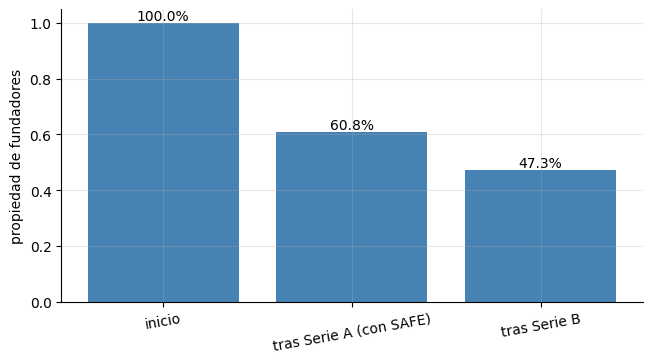

Lectura:
  Los fundadores terminan con 47.3%. La Serie B vende 20% nominal, pero la retencion fue 0.778 (no 0.80): el pool al 10% post se vuelve a llenar dentro del pre-money y diluye a todos los existentes.


In [10]:
fig, ax = plt.subplots(figsize=(7.5, 3.8)); ax.bar(traj.index, traj["fundadores"], color="steelblue"); ax.set_ylabel("propiedad de fundadores")
for i, v in enumerate(traj["fundadores"]): ax.text(i, v + .01, f"{v:.1%}", ha="center")
plt.xticks(rotation=10); plt.show()
print("Lectura:")
print(f"  Los fundadores terminan con {f2:.1%}. La Serie B vende {10 / 50:.0%} nominal, pero la retencion fue {f2 / f1:.3f} (no 0.80): el pool al 10% post se vuelve a llenar dentro del pre-money y diluye a todos los existentes.")

## 5. Cascada de liquidación

A la salida con valor $E$ se paga primero a las **preferencias** y luego se reparte el resto entre común, quienes convirtieron y las series **participantes**. Todas las series son *pari passu*. Las series:

- **SAFE_1, SAFE_2 y Serie A:** 1× no participantes (los SAFE convertidos reciben acciones preferidas "sombra" con preferencia igual a su inversión).
- **Serie B (10 M):** se compara entre tres términos: 1× no participante, 1× **participante** (cobra la preferencia *y además* su parte) y 2× no participante.

La decisión de convertir de cada serie no participante se resuelve por **iteración hasta el equilibrio**. El pool se trata como común totalmente otorgado (supuesto conservador para los fundadores).

In [11]:
def cascada(E, series, comunes):
    conv = {s["nombre"]: False for s in series}
    def pagar(conv):
        pagos = {k: 0.0 for k in comunes}; pagos.update({s["nombre"]: 0.0 for s in series})
        prefs = {s["nombre"]: s["pref"] for s in series if not conv[s["nombre"]]}
        P = sum(prefs.values()); cobra = min(E, P)
        for n, v in prefs.items(): pagos[n] += cobra * v / P
        resto = E - cobra; part = dict(comunes)
        for s in series:
            if conv[s["nombre"]] or s["part"]: part[s["nombre"]] = s["acc"]
        A = sum(part.values())
        for n, v in part.items(): pagos[n] += resto * v / A
        return pagos
    for _ in range(50):
        base = pagar(conv); cambio = False
        for s in series:
            if s["part"]: continue
            alt = dict(conv); alt[s["nombre"]] = not conv[s["nombre"]]
            if pagar(alt)[s["nombre"]] > base[s["nombre"]] + 1e-9: conv = alt; cambio = True; break
        if not cambio: break
    return pagar(conv), conv

def armar(t, tipo_B):
    comunes = {k: t[k] for k in ("fund_A", "fund_B", "pool")}
    ser = [{"nombre": "SAFE_1", "acc": t["SAFE_1"], "pref": 500_000.0, "part": False}, {"nombre": "SAFE_2", "acc": t["SAFE_2"], "pref": 250_000.0, "part": False},
           {"nombre": "SerieA", "acc": t["SerieA"], "pref": 3_000_000.0, "part": False}]
    mult, part = {"1x_no_part": (1, False), "1x_participante": (1, True), "2x_no_part": (2, False)}[tipo_B]
    ser.append({"nombre": "SerieB", "acc": t["SerieB"], "pref": 10_000_000.0 * mult, "part": part})
    return ser, comunes

TERMINOS = ("1x_no_part", "1x_participante", "2x_no_part")
Es = np.array([2, 5, 10, 15, 25, 40, 60, 100, 200, 500]) * 1e6
filas = []
for term in TERMINOS:
    ser, com = armar(tB, term)
    for E in Es:
        pg, cv = cascada(E, ser, com); fund = pg["fund_A"] + pg["fund_B"]
        filas.append({"terminos_B": term, "salida_M": E / 1e6, "fundadores_M": fund / 1e6, "fund_%_de_salida": fund / E, "SerieB_M": pg["SerieB"] / 1e6, "B_convierte": cv["SerieB"]})
casc = pd.DataFrame(filas)
casc.pivot(index="salida_M", columns="terminos_B", values="fundadores_M").round(2)

terminos_B,1x_no_part,1x_participante,2x_no_part
salida_M,,,
2.0000,0.0000,0.0000,0.0000
5.0000,0.0000,0.0000,0.0000
10.0000,0.0000,0.0000,0.0000
15.0000,1.0300,0.7600,0.0000
25.0000,8.8100,6.7200,1.0300
40.0000,17.7400,14.1900,11.8200
60.0000,28.3800,23.6500,23.6500
100.0000,47.3000,42.5700,47.3000
200.0000,94.6000,89.8700,94.6000


In [12]:
pv = casc.pivot(index="salida_M", columns="terminos_B", values="fund_%_de_salida")
print("Parte de la salida que va a los fundadores:"); print(pv.round(3).to_string())
prop = ownB[["fund_A", "fund_B"]].sum()
print("\nLectura:")
print(f"  Propiedad nominal de los fundadores tras la Serie B: {prop:.1%}.")
print(f"  Salida de 15 M (bajo el post-money de 50 M): 1x no part. -> fundadores {pv.loc[15, '1x_no_part']:.1%}; participante -> {pv.loc[15, '1x_participante']:.1%}; 2x -> {pv.loc[15, '2x_no_part']:.1%}. Las preferencias absorben la salida casi por completo.")
print(f"  Salida de 100 M: {pv.loc[100, '1x_no_part']:.1%} / {pv.loc[100, '1x_participante']:.1%} / {pv.loc[100, '2x_no_part']:.1%}. La clausula participante sigue costando a los fundadores incluso cuando todos habrian convertido.")
print(f"  Salida de 500 M: {pv.loc[500, '1x_no_part']:.1%} / {pv.loc[500, '1x_participante']:.1%} / {pv.loc[500, '2x_no_part']:.1%}: converge a la propiedad nominal solo cuando la preferencia pierde peso (y el participante nunca converge del todo).")

Parte de la salida que va a los fundadores:
terminos_B  1x_no_part  1x_participante  2x_no_part
salida_M                                           
2.0000          0.0000           0.0000      0.0000
5.0000          0.0000           0.0000      0.0000
10.0000         0.0000           0.0000      0.0000
15.0000         0.0690           0.0510      0.0000
25.0000         0.3520           0.2690      0.0410
40.0000         0.4430           0.3550      0.2960
60.0000         0.4730           0.3940      0.3940
100.0000        0.4730           0.4260      0.4730
200.0000        0.4730           0.4490      0.4730
500.0000        0.4730           0.4640      0.4730

Lectura:
  Propiedad nominal de los fundadores tras la Serie B: 47.3%.
  Salida de 15 M (bajo el post-money de 50 M): 1x no part. -> fundadores 6.9%; participante -> 5.1%; 2x -> 0.0%. Las preferencias absorben la salida casi por completo.
  Salida de 100 M: 47.3% / 42.6% / 47.3%. La clausula participante sigue costando a los fund

Umbral analitico de conversion: 20.00 M. Debajo convierte: False, cobra 4.000 M (pref 4.000). Encima convierte: True, cobra 4.080 M (= 4.080).


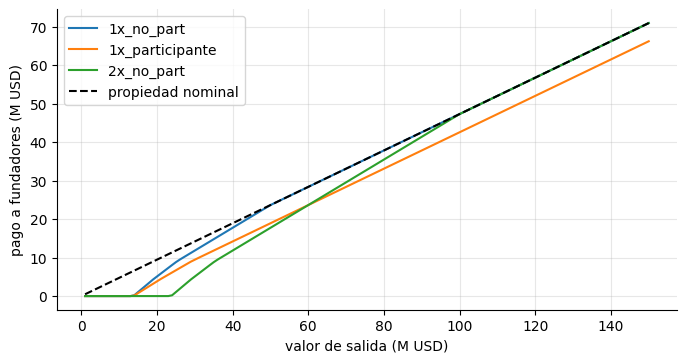

In [13]:
# Puntos de conversion: verificacion analitica con UNA sola serie no participante
ser1 = [{"nombre": "X", "acc": 2_000_000.0, "pref": 4_000_000.0, "part": False}]; com1 = {"c": 8_000_000.0}
umbral = 4_000_000.0 * 10_000_000.0 / 2_000_000.0                                # E* = L*T/s
bajo = cascada(umbral * 0.98, ser1, com1); alto = cascada(umbral * 1.02, ser1, com1)
print(f"Umbral analitico de conversion: {umbral / 1e6:.2f} M. Debajo convierte: {bajo[1]['X']}, cobra {bajo[0]['X'] / 1e6:.3f} M (pref 4.000). Encima convierte: {alto[1]['X']}, cobra {alto[0]['X'] / 1e6:.3f} M (= {umbral * 1.02 * 0.2 / 1e6:.3f}).")
# curva de pago de fundadores
grid = np.linspace(1e6, 150e6, 150)
fig, ax = plt.subplots(figsize=(8, 3.9))
for term in TERMINOS:
    ser, com = armar(tB, term); ax.plot(grid / 1e6, [sum(cascada(E, ser, com)[0][k] for k in ("fund_A", "fund_B")) / 1e6 for E in grid], label=term)
ax.plot(grid / 1e6, prop * grid / 1e6, "k--", label="propiedad nominal"); ax.set_xlabel("valor de salida (M USD)"); ax.set_ylabel("pago a fundadores (M USD)"); ax.legend(); plt.show()

## 6. Monte Carlo de la salida

La salida es incierta. Se modela: con probabilidad 40 % la empresa fracasa y se liquida por $E\sim U(0,\,8\text{ M})$; con 60 % tiene una salida lognormal de mediana 90 M y $\sigma=1{,}0$. Se calcula el pago esperado de los fundadores y su distribución para los tres términos de la Serie B.

In [14]:
rng = np.random.default_rng(SEED); NS = 4000
exito = rng.random(NS) < 0.6
Ev = np.where(exito, np.exp(rng.normal(np.log(90e6), 1.0, NS)), rng.uniform(0, 8e6, NS))
res = {}
for term in TERMINOS:
    ser, com = armar(tB, term); res[term] = np.array([sum(cascada(E, ser, com)[0][k] for k in ("fund_A", "fund_B")) for E in Ev])
nominal = prop * Ev
mc = pd.DataFrame({t: {"pago_esperado_M": res[t].mean() / 1e6, "mediana_M": np.median(res[t]) / 1e6, "P(pago<1M)": (res[t] < 1e6).mean(), "P10_M": np.percentile(res[t], 10) / 1e6, "P90_M": np.percentile(res[t], 90) / 1e6} for t in TERMINOS}).T
mc.loc["sin preferencias (nominal)"] = [nominal.mean() / 1e6, np.median(nominal) / 1e6, (nominal < 1e6).mean(), np.percentile(nominal, 10) / 1e6, np.percentile(nominal, 90) / 1e6]
print(f"Salida esperada: {Ev.mean() / 1e6:,.1f} M; mediana {np.median(Ev) / 1e6:,.1f} M")
mc.round(3)

Salida esperada: 94.6 M; mediana 34.0 M


,pago_esperado_M,mediana_M,P(pago<1M),P10_M,P90_M
1x_no_part,43.5430,14.1700,0.4210,0.0000,119.3860
1x_participante,41.0930,11.3360,0.4230,0.0000,114.6570
2x_no_part,42.2090,8.0490,0.4580,0.0000,119.3860
sin preferencias (nominal),44.7410,16.0660,0.1000,1.0010,119.3860


In [15]:
costo = {t: 1 - mc.loc[t, "pago_esperado_M"] / mc.loc["sin preferencias (nominal)", "pago_esperado_M"] for t in TERMINOS}
print("Lectura:")
print(f"  Pago esperado de los fundadores: {mc.loc['sin preferencias (nominal)', 'pago_esperado_M']:.2f} M sin preferencias; {mc.loc['1x_no_part', 'pago_esperado_M']:.2f} M con 1x no part., {mc.loc['1x_participante', 'pago_esperado_M']:.2f} M con 1x participante, {mc.loc['2x_no_part', 'pago_esperado_M']:.2f} M con 2x.")
print(f"  Costo de las preferencias para los fundadores (frente al reparto nominal): " + ", ".join(f"{t} {c:.1%}" for t, c in costo.items()) + ".")
print(f"  La probabilidad de recibir menos de 1 M es {mc.loc['1x_no_part', 'P(pago<1M)']:.0%} con 1x no part. frente a {mc.loc['sin preferencias (nominal)', 'P(pago<1M)']:.0%} sin preferencias.")
print("  El valor de las clausulas esta en el escenario malo/medio, no en el exito grande: por eso se negocian aunque 'solo importen si sale mal'.")

Lectura:
  Pago esperado de los fundadores: 44.74 M sin preferencias; 43.54 M con 1x no part., 41.09 M con 1x participante, 42.21 M con 2x.
  Costo de las preferencias para los fundadores (frente al reparto nominal): 1x_no_part 2.7%, 1x_participante 8.2%, 2x_no_part 5.7%.
  La probabilidad de recibir menos de 1 M es 42% con 1x no part. frente a 10% sin preferencias.
  El valor de las clausulas esta en el escenario malo/medio, no en el exito grande: por eso se negocian aunque 'solo importen si sale mal'.


## 7. Pruebas automáticas

In [16]:
# 7.1 invariantes de la ronda con SAFE: suma de propiedad = 1, post-money implicito, pool objetivo, inversor = inv/post
assert abs(ownA.sum() - 1) < 1e-12 and abs(sum(tA.values()) * pA - 15_000_000) < 1e-3
assert abs(ownA["pool"] - 0.10) < 1e-9 and abs(ownA["SerieA"] - 0.20) < 1e-9
# 7.2 SAFE_1 por cap: I/C de la capitalizacion con SAFE y sin el pool nuevo
cap_sin_pool_nuevo = S0 + iA["sh_safe"].sum(); assert abs(iA["sh_safe"][0] / cap_sin_pool_nuevo - 500_000 / 5_000_000) < 1e-9
# 7.3 SAFE_2 convierte por el mejor precio (cap o descuento), y nunca peor que el precio de la ronda con descuento
assert sf.loc["SAFE_2", "precio_conv"] <= min(sf.loc["SAFE_2", "precio_por_cap"], sf.loc["SAFE_2", "precio_por_desc"]) + 1e-9
assert sf.loc["SAFE_1", "precio_conv"] < pA
# 7.3b el descuento muerde con precios de ronda bajos y no con altos
assert (barrido['muerde'] == 'descuento').any() and (barrido['muerde'] == 'cap').any()
# 7.4 option pool shuffle: el inversor compra siempre 20%; los fundadores bajan con el pool; pool final = objetivo
assert np.allclose(pw["inversor"], 0.20) and pw["fundadores"].is_monotonic_decreasing and np.allclose(pw["pool"], pw.index.values)
assert np.allclose(pw["fundadores"] + pw["pool"] + pw["inversor"], 1)
# 7.5 trayectoria: la retencion de la Serie B coincide con el calculo independiente y es menor que 0.80
assert abs(f2 / f1 - ret_indep) < 1e-12 and f2 / f1 < 0.80 and abs(ownB["pool"] - 0.10) < 1e-9 and abs(ownB["SerieB"] - 0.20) < 1e-9
# 7.6 cascada: los pagos suman la salida, son monotonos en E, y nadie cobra menos que 0
for term in TERMINOS:
    ser, com = armar(tB, term); prev = None
    for E in (1e6, 5e6, 14e6, 33e6, 80e6, 400e6):
        pg, cv = cascada(E, ser, com); assert abs(sum(pg.values()) - E) < 1e-4 and min(pg.values()) >= -1e-9
        if prev is not None: assert all(pg[k] >= prev[k] - 1e-6 for k in ("fund_A", "fund_B", "SerieB", "SerieA")), (term, E)
        prev = pg
# 7.7 punto de conversion analitico
assert (not bajo[1]["X"]) and abs(bajo[0]["X"] - 4_000_000) < 1e-6 and alto[1]["X"] and abs(alto[0]["X"] - umbral * 1.02 * 0.2) < 1e-4
# 7.8 la clausula participante y el 2x cuestan a los fundadores frente al 1x no participante en TODA la grilla
for E in Es:
    a = pv.loc[E / 1e6]; assert a["1x_participante"] <= a["1x_no_part"] + 1e-9 and a["2x_no_part"] <= a["1x_no_part"] + 1e-9
# 7.9 Monte Carlo: el pago esperado con preferencias es menor que el nominal y ordenado por dureza de los terminos
assert mc.loc["1x_no_part", "pago_esperado_M"] < mc.loc["sin preferencias (nominal)", "pago_esperado_M"]
assert mc.loc["1x_participante", "pago_esperado_M"] < mc.loc["1x_no_part", "pago_esperado_M"] and mc.loc["2x_no_part", "pago_esperado_M"] < mc.loc["1x_no_part", "pago_esperado_M"]
print("Todas las pruebas pasaron.")

Todas las pruebas pasaron.


## Conclusiones y límites

| Paso | Qué se encontró | Decisión |
|---|---|---|
| SAFE | Convierten antes de la ronda y diluyen a los fundadores, no al inversor de la ronda | Modelar siempre la conversión; el precio efectivo depende del mejor entre cap y descuento |
| Option pool shuffle | El pool dentro del pre-money reduce la valoración efectiva de los fundadores | Negociar el pre-money efectivo, no el nominal |
| Dilución | Cada ronda retiene menos que 1 − (% vendido) por el pool | Proyectar la propiedad con el motor, no a ojo |
| Cascada | Con salidas bajas las preferencias absorben casi todo; la cláusula participante sigue costando aun en salidas altas | Comparar términos por el pago esperado, no solo por el precio |
| Monte Carlo | En este escenario las preferencias cuestan entre ~3 % y ~8 % del pago esperado de los fundadores, pero bajan la mediana y multiplican la probabilidad de recibir poco | Mirar la mediana y la cola baja, no solo el pago esperado |

**Límites que no deben ocultarse**

- Se omiten vencimientos de opciones (*vesting*), *anti-dilution*, dividendos acumulados, deuda y prioridad entre series (todas *pari passu*).
- El pool se trata como totalmente otorgado en la cascada; si no se otorga, los fundadores reciben más.
- Los SAFE se modelan solo post-money; los pre-money y las notas convertibles tienen otra mecánica.
- Los términos y distribuciones de la salida son hipotéticos; no son consejo legal ni de inversión.